# Aldol addition

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/aldol_analysis.py) · [Model inputs](../../examples/tcs/aldol.gml)

One NoEdge condition changes which compositions exist and which signed terms cancel.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=651f6501" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=72e9e137" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#f2f3f4;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><span aria-disabled="true" title="Composition audit only" style="color:#737d83;display:inline-block;vertical-align:top">3 · Observable discovery<small style="display:block;font-size:10px;font-weight:400">Composition audit only</small></span></span><span data-topic="ode" style="background:#f2f3f4;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Not analysed" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Not analysed</small></span> &amp; <span aria-disabled="true" title="Not analysed" style="color:#737d83;display:inline-block;vertical-align:top">pJC<small style="display:block;font-size:10px;font-weight:400">Not analysed</small></span></span><span data-topic="initial" style="background:#f2f3f4;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><span aria-disabled="true" title="Composition audit only" style="color:#737d83;display:inline-block;vertical-align:top">5 · Initial states<small style="display:block;font-size:10px;font-weight:400">Composition audit only</small></span></span><span data-topic="dynamics" style="background:#f2f3f4;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><span aria-disabled="true" title="Composition audit only" style="color:#737d83;display:inline-block;vertical-align:top">6 · Dynamics<small style="display:block;font-size:10px;font-weight:400">Composition audit only</small></span></span></nav>

In [1]:
from pathlib import Path
import sys
NOTEBOOKS = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "paper_view.py").is_file())
PACKAGE = NOTEBOOKS.parent
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / "src"), str(PACKAGE)]
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import visual_view as visual

EXAMPLE = 'visual-aldol'
run = visual.Run(EXAMPLE)
import inspection as files

<h2 style="background:#e7f3e9;padding:14px 18px;border-radius:6px">Model</h2>

The aldol rule retains its NoEdge condition. We change only the query condition. A valence filter checks atom labels and bond-order sums (C ≤ 4, O ≤ 2, H ≤ 1). This example studies local compositions, rather than a full chemical state space.


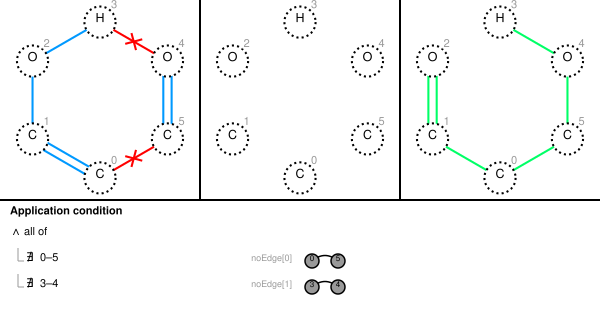

In [2]:
from mfobs.state_space import covalent_compositions
from examples.tcs.replay import load_rules
Omega = covalent_compositions()
inputs = load_rules(omega=Omega)
visual.rules([('Aldol addition · L ← K → R', inputs['aldol'])])

Blue: deleted · Green: created · Red ×: NoEdge. Vertex numbers identify the atoms in the GML.

<h2 style="background:#fbe9e9;padding:14px 18px;border-radius:6px">Query</h2>

Count the same pattern with and without **NoEdge(0, 5)**. Each picture shows the input of its identity rule.

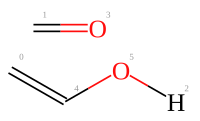

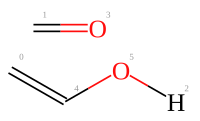

In [3]:
visual.rules([
    ("Without query NoEdge", inputs["query_unconditioned"]),
    ("With query NoEdge", inputs["query_conditioned"]),
], identity=True)

<h2 style="background:#e8f0fb;padding:14px 18px;border-radius:6px">Composition</h2>

Compose in both orders: reaction → query counts **after**; query → reaction counts **before**. The signed contribution is after minus before.

In [4]:
from examples.tcs.compare_conditions import compare_conditions
with run.capture('compositions'):
    comparison = compare_conditions(run.path / 'compositions', export_candidates=True)
from examples.tcs.table1 import export_computed_table
with run.capture('plain-table'):
    export_computed_table(run.path / 'plain-table')

In [5]:
visual.table([
    {"Query NoEdge": label,
     "After compositions": comparison["variants"][key]["orders"]["reaction_then_query"]["filtered"],
     "Before compositions": comparison["variants"][key]["orders"]["query_then_reaction"]["filtered"],
     "Nonzero signed terms": comparison["variants"][key]["nonzero_signed_terms"]}
    for label, key in [("absent", "reaction_noedge"), ("present", "reaction_and_query_noedge")]
], index="Query NoEdge")

,After compositions,Before compositions,Nonzero signed terms
Query NoEdge,,,
absent,13,18,13
present,10,18,18


In [6]:
aldol_files = files.aldol_tables(
    comparison, run.path / "compositions", run.path / "plain-table", run)

Class,Rules,After · TCS,After · MolFoundry,Before · TCS,Before · MolFoundry,C1,C2
r+,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">MolFoundry GML",0,0,1,1,,
r2,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%2010%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%2011%20label%20%22C%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%209%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%2010%20target%2011%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">MolFoundry GML",1,1,1,1,,
r7,"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22O%22%20%5

Rule (GML),After,Before,After − before
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%208%20target%209%20label%20%22-%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22H%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%209%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%09constrainNoEdge%20%5B%0A%09%09source%200%0A%09%09target%205%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">1",0,1,-1
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">2",0,1,-1
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%209%20target%200%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22O%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20

Rule (GML),After,Before,After − before
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">1",0,1,-1
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%205%20label%20%22-%22%20%5D%0A%09%5D%0A%5D"" target=""_blank"" rel=""noopener"">2",1,0,1
"<a href=""https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22%20%2Acommon%2A%20%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22O%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%209%20label%20%22O%22%20%5D%0A%09%09edge%20%5B%20source%205%20target%206%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%206%20target%207%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%207%20target%208%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%209%20target%200%20label%20%22%3D%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22%3D%22%20%5D%0A%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%203%20target%

The query condition excludes three after-count classes (`r68`, `r73`, `r120`). It also prevents cancellations. Below is the selected `r180` pair: its positive graph spans coincide, but its application conditions differ.

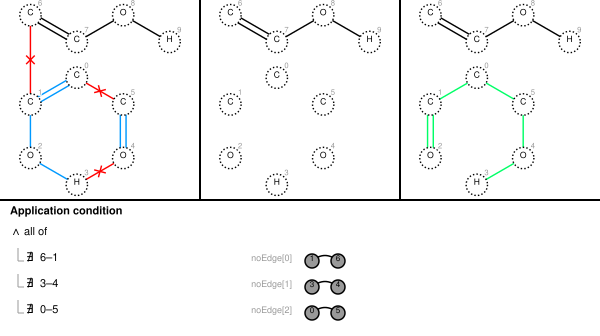

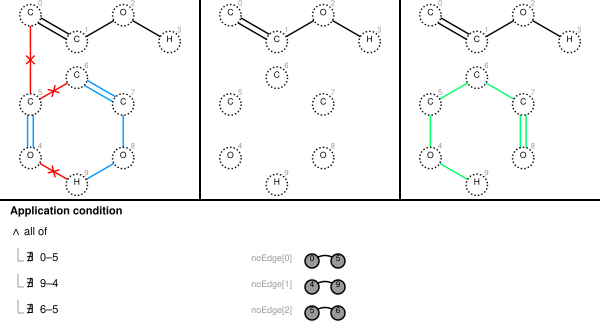

In [7]:
pair = comparison["comparison"]["selected_r180"]["reaction_and_query_noedge"]
visual.rules([(("after" if row["after"] else "before") + "-count composite",
              (run.path / "compositions" / row["gml"]).read_text(encoding='utf-8'))
              for row in pair])

Source: Behr et al., *Rewriting Theory for the Life Sciences*, §8.3, [doi:10.1016/j.tcs.2021.07.026](https://doi.org/10.1016/j.tcs.2021.07.026).

[← All examples](../paper_examples.ipynb)